In [1]:
%pip -q install numpy pandas scipy statsmodels matplotlib

In [2]:
from pathlib import Path
from itertools import permutations
from collections import Counter
from importlib.metadata import version
from datetime import datetime, timezone

import json
import math
import platform
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar
from statsmodels.stats.multitest import multipletests


# ------------------------------------------------------------
# Ranking definitions
# ------------------------------------------------------------

EVENT_LABELS = tuple("ABCD")
VALID_LABELS = set(EVENT_LABELS)

# Alphabetical order also defines the final tie-breaking rule.
ALL_RANKINGS = [
    "".join(items) for items in permutations(EVENT_LABELS)
]

MAX_KENDALL_DISTANCE = math.comb(len(EVENT_LABELS), 2)


# ------------------------------------------------------------
# Aggregation and statistical settings
# ------------------------------------------------------------

ORNESS_GRID = [i / 10 for i in range(11)]
ANCHOR_ORNESS = [0.0, 0.5, 1.0]

SCORE_ATOL = 1e-12
SCORE_RTOL = 0.0

# Explicit settings for this reconstruction.
SIGNIFICANCE_LEVEL = 0.05
RANDOM_SEED = 20260914
BOOTSTRAP_REPS = 5000

# Comparison families will be defined before statistical testing.


# ------------------------------------------------------------
# Model and column labels
# ------------------------------------------------------------

MODEL_LABELS = {
    "gpt": "GPT-5.1",
    "claude": "Claude Sonnet 4.5",
}

ARCHITECTURE_COLUMNS = {
    "Standard": "Vanilla_Ans",
    "Structured": "Single_Ans",
    "Heterogeneous": "Hetero_Ans",
}

DOMAIN_MAP = {
    1: "Economics & Policy",
    2: "Business",
    3: "Supply Chain Management",
}

EXPECTED_SOURCE_QUESTIONS = 650


# ------------------------------------------------------------
# Local folders
# ------------------------------------------------------------

# Files uploaded to Colab will be placed here in Section 3.
PROJECT_DIR = Path("/content/owamas")
DATA_DIR = PROJECT_DIR / "data"

# A separate folder preserves outputs from each analysis run.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = PROJECT_DIR / "outputs" / RUN_ID

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
AUDIT_DIR = OUTPUT_DIR / "audit"

for folder in (DATA_DIR, TABLE_DIR, FIGURE_DIR, AUDIT_DIR):
    folder.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Record the environment and settings
# ------------------------------------------------------------

PACKAGES = ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]
PACKAGE_VERSIONS = {name: version(name) for name in PACKAGES}

settings = {
    "run_id": RUN_ID,
    "analysis_status": "Reconstruction after inspection of earlier results",
    "python_version": platform.python_version(),
    "package_versions": PACKAGE_VERSIONS,
    "event_labels": list(EVENT_LABELS),
    "orness_grid": ORNESS_GRID,
    "anchor_orness": ANCHOR_ORNESS,
    "score_absolute_tolerance": SCORE_ATOL,
    "score_relative_tolerance": SCORE_RTOL,
    "significance_level": SIGNIFICANCE_LEVEL,
    "resampling_seed": RANDOM_SEED,
    "bootstrap_repetitions": BOOTSTRAP_REPS,
    "comparison_families": "To be defined in the statistical-analysis section",
}

with (AUDIT_DIR / "analysis_settings.json").open("w") as file:
    json.dump(settings, file, indent=2)

# Exact versions can be used to recreate this run's environment.
requirements = "\n".join(
    f"{name}=={installed_version}"
    for name, installed_version in PACKAGE_VERSIONS.items()
)
(AUDIT_DIR / "requirements.txt").write_text(requirements + "\n")

print("Setup complete.")
print(f"Candidate rankings: {len(ALL_RANKINGS)}")
print(f"Maximum Kendall distance: {MAX_KENDALL_DISTANCE}")
print(f"Orness grid: {ORNESS_GRID}")
print(f"Output folder: {OUTPUT_DIR}")
print("\nPackage versions:")
print(pd.Series(PACKAGE_VERSIONS).to_string())

Setup complete.
Candidate rankings: 24
Maximum Kendall distance: 6
Orness grid: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Output folder: /content/owamas/outputs/20261017T134646_300295Z

Package versions:
numpy           2.1.3
pandas          2.2.3
scipy          1.16.3
statsmodels    0.15.0
matplotlib     3.10.0


In [3]:
from google.colab import files
import hashlib
import json

INPUT_FILENAMES = {
    "gpt": "econlogic_gpt_results.csv",
    "claude": "econlogic_claude1_results.csv",
}

# Run the notebook's setup cell first, so DATA_DIR and AUDIT_DIR exist.
DATA_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR.mkdir(parents=True, exist_ok=True)


required_files = [
    "econlogic_gpt_results.csv",
    "econlogic_claude1_results.csv",
]

print("Select both required CSV files from your computer.")
uploaded = files.upload()

# Restore the expected names if Colab adds (1), (2), etc.
import re
uploaded = {
    re.sub(r" \(\d+\)(?=\.csv$)", "", name): content
    for name, content in uploaded.items()
}

missing = [name for name in required_files if name not in uploaded]
if missing:
    raise FileNotFoundError(
        "Missing required files: " + ", ".join(missing)
        + ". Run this cell again and select both files."
    )

manifest = []
for name in required_files:
    content = uploaded[name]
    (DATA_DIR / name).write_bytes(content)
    manifest.append({
        "filename": name,
        "bytes": len(content),
        "sha256": hashlib.sha256(content).hexdigest(),
    })

(AUDIT_DIR / "input_manifest.json").write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print("Both input files are ready. Continue with data validation.")

Select both required CSV files from your computer.


Saving econlogic_claude1_results.csv to econlogic_claude1_results.csv
Saving econlogic_gpt_results.csv to econlogic_gpt_results.csv
Both input files are ready. Continue with data validation.


In [4]:
REQUIRED_COLUMNS = [
    "id", "domain_class", "question", "A", "B", "C", "D",
    "ground_truth", "Vanilla_Ans", "Single_Ans",
    "Hetero_Ans", "Homo_Ans", "Homo_Log",
]


def load_prediction_file(model_key):
    path = DATA_DIR / INPUT_FILENAMES[model_key]

    df = pd.read_csv(
        path,
        dtype={"id": "string"},
        keep_default_na=False,
    )

    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
    if missing_columns:
        raise ValueError(
            f"{model_key}: missing columns {missing_columns}"
        )

    df["id"] = df["id"].str.strip()

    if df["id"].isna().any() or df["id"].eq("").any():
        raise ValueError(f"{model_key}: missing question IDs.")

    duplicated = df.loc[
        df["id"].duplicated(keep=False), "id"
    ].tolist()

    if duplicated:
        raise ValueError(
            f"{model_key}: duplicate question IDs: {duplicated[:10]}"
        )

    if len(df) != EXPECTED_SOURCE_QUESTIONS:
        raise ValueError(
            f"{model_key}: expected {EXPECTED_SOURCE_QUESTIONS} "
            f"questions, found {len(df)}."
        )

    domain_codes = pd.to_numeric(
        df["domain_class"], errors="coerce"
    )

    invalid_domains = ~domain_codes.isin(DOMAIN_MAP.keys())
    if invalid_domains.any():
        bad_ids = df.loc[invalid_domains, "id"].tolist()
        raise ValueError(
            f"{model_key}: invalid domain codes for IDs {bad_ids[:10]}"
        )

    df["domain_class"] = domain_codes.astype(int)
    df["domain"] = df["domain_class"].map(DOMAIN_MAP)

    return df


raw_gpt = load_prediction_file("gpt")
raw_claude = load_prediction_file("claude")

# Compare IDs before aligning the rows.
gpt_ids = set(raw_gpt["id"])
claude_ids = set(raw_claude["id"])

if gpt_ids != claude_ids:
    raise ValueError(
        "Question IDs differ between files. "
        f"GPT-only: {sorted(gpt_ids - claude_ids)[:10]}; "
        f"Claude-only: {sorted(claude_ids - gpt_ids)[:10]}"
    )

# Match by question ID, not by CSV row position.
gpt_aligned = raw_gpt.set_index("id").sort_index()
claude_aligned = raw_claude.set_index("id").reindex(
    gpt_aligned.index
)


def normalise_text(series):
    return (
        series.astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )


def normalise_ground_truth(value):
    compact = re.sub(r"[^A-D]", "", str(value).upper())

    if len(compact) == 4 and set(compact) == VALID_LABELS:
        return compact

    return None


alignment_records = []

for column in ["question", "A", "B", "C", "D"]:
    matches = (
        normalise_text(gpt_aligned[column])
        == normalise_text(claude_aligned[column])
    )

    alignment_records.append({
        "field": column,
        "matching_rows": int(matches.sum()),
        "total_rows": len(matches),
    })

    if not matches.all():
        bad_ids = matches.index[~matches].tolist()
        raise ValueError(
            f"Content mismatch in '{column}' for IDs {bad_ids[:10]}"
        )

gpt_gt = gpt_aligned["ground_truth"].map(normalise_ground_truth)
claude_gt = claude_aligned["ground_truth"].map(normalise_ground_truth)

if gpt_gt.isna().any() or claude_gt.isna().any():
    raise ValueError("Invalid ground-truth rankings found.")

for field, matches in [
    ("ground_truth", gpt_gt.eq(claude_gt)),
    (
        "domain_class",
        gpt_aligned["domain_class"].eq(
            claude_aligned["domain_class"]
        ),
    ),
]:
    alignment_records.append({
        "field": field,
        "matching_rows": int(matches.sum()),
        "total_rows": len(matches),
    })

    if not matches.all():
        bad_ids = matches.index[~matches].tolist()
        raise ValueError(
            f"Mismatch in '{field}' for IDs {bad_ids[:10]}"
        )

pd.DataFrame(alignment_records).to_csv(
    AUDIT_DIR / "input_alignment.csv",
    index=False,
)

domain_counts = pd.DataFrame({
    MODEL_LABELS["gpt"]: raw_gpt["domain"].value_counts(),
    MODEL_LABELS["claude"]: raw_claude["domain"].value_counts(),
}).fillna(0).astype(int)

domain_counts.to_csv(AUDIT_DIR / "input_domain_counts.csv")

print("Input validation passed.")
print(f"GPT questions: {len(raw_gpt)}")
print(f"Claude questions: {len(raw_claude)}")
print("IDs, question content, ground truth, and domain labels align.")
print("\nDomain counts:")
print(domain_counts.to_string())
print("\nNo prediction exclusions have been applied yet.")

Input validation passed.
GPT questions: 650
Claude questions: 650
IDs, question content, ground truth, and domain labels align.

Domain counts:
                         GPT-5.1  Claude Sonnet 4.5
domain                                             
Business                     303                303
Economics & Policy           200                200
Supply Chain Management      147                147

No prediction exclusions have been applied yet.


In [5]:
def parse_rank(value):
    """Return a complete A–D permutation, or None."""
    if pd.isna(value):
        return None

    text = str(value).strip().upper()

    if not text or "EXTRACTION_FAILED" in text:
        return None

    tags = re.findall(
        r"<ANSWER>\s*([^<]+?)\s*</ANSWER>",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )

    if tags:
        text = tags[-1].strip().upper()

    compact = re.sub(r"[^A-D]", "", text)

    if len(compact) == 4 and set(compact) == VALID_LABELS:
        return compact

    return None


def extract_homogeneous_agents(log_text):
    """Extract the last tagged answer from each agent's log section."""
    result = {"A1": None, "A2": None, "A3": None}

    if pd.isna(log_text):
        return result

    text = str(log_text)

    markers = list(re.finditer(
        r"===\s*(A1|A2|A3|META)\s*===",
        text,
        flags=re.IGNORECASE,
    ))

    sections = {}

    for i, marker in enumerate(markers):
        label = marker.group(1).upper()
        start = marker.end()
        end = (
            markers[i + 1].start()
            if i + 1 < len(markers)
            else len(text)
        )
        sections[label] = text[start:end]

    for label in result:
        tags = re.findall(
            r"<ANSWER>\s*([^<]+?)\s*</ANSWER>",
            sections.get(label, ""),
            flags=re.IGNORECASE | re.DOTALL,
        )

        if tags:
            result[label] = parse_rank(tags[-1])

    return result


def prepare_model_data(raw_df, model_key):
    """Create analysis columns without changing the raw dataframe."""
    df = raw_df.copy()
    df["model"] = MODEL_LABELS[model_key]

    df["GT"] = df["ground_truth"].map(parse_rank)

    for analysis_name, source_column in ARCHITECTURE_COLUMNS.items():
        df[analysis_name] = df[source_column].map(parse_rank)

    df["Consensus_Meta"] = df["Homo_Ans"].map(parse_rank)

    agents = pd.DataFrame(
        df["Homo_Log"].map(extract_homogeneous_agents).tolist(),
        index=df.index,
    )

    for label in ["A1", "A2", "A3"]:
        df[label] = agents[label]

    return df


# Basic parser checks.
assert parse_rank("A, B, C, D") == "ABCD"
assert parse_rank("d → c → b → a") == "DCBA"
assert parse_rank("AABC") is None
assert parse_rank("ABC") is None
assert parse_rank("EXTRACTION_FAILED") is None
assert parse_rank(
    "<ANSWER>ABCD</ANSWER><ANSWER>DCBA</ANSWER>"
) == "DCBA"

gpt_data = prepare_model_data(raw_gpt, "gpt")
claude_data = prepare_model_data(raw_claude, "claude")

RANKING_FIELDS = [
    "GT",
    "Standard",
    "Structured",
    "Heterogeneous",
    "Consensus_Meta",
    "A1",
    "A2",
    "A3",
]

validation_records = []
invalid_records = []

for df in [gpt_data, claude_data]:
    model = df["model"].iloc[0]

    for field in RANKING_FIELDS:
        valid = df[field].isin(ALL_RANKINGS)

        validation_records.append({
            "model": model,
            "field": field,
            "total_questions": len(df),
            "valid_rankings": int(valid.sum()),
            "invalid_rankings": int((~valid).sum()),
        })

        for question_id in df.loc[~valid, "id"]:
            invalid_records.append({
                "model": model,
                "id": question_id,
                "field": field,
            })

    if not df["GT"].isin(ALL_RANKINGS).all():
        raise ValueError(f"{model}: invalid ground truth detected.")

ranking_validation = pd.DataFrame(validation_records)

invalid_rankings = pd.DataFrame(
    invalid_records,
    columns=["model", "id", "field"],
)

ranking_validation.to_csv(
    AUDIT_DIR / "ranking_validation.csv", index=False
)

invalid_rankings.to_csv(
    AUDIT_DIR / "invalid_ranking_ids.csv", index=False
)

# Save canonical rankings separately from the original input files.
export_columns = ["id", "model", "domain"] + RANKING_FIELDS

gpt_data[export_columns].to_csv(
    AUDIT_DIR / "parsed_gpt_rankings.csv", index=False
)

claude_data[export_columns].to_csv(
    AUDIT_DIR / "parsed_claude_rankings.csv", index=False
)

print("Ranking parsing complete.")
print(ranking_validation.to_string(index=False))

print("\nInvalid ranking IDs:")
if invalid_rankings.empty:
    print("None.")
else:
    print(invalid_rankings.to_string(index=False))

print("\nAll 650 questions per model remain in the prepared data.")
print("Experiment-specific exclusions will be applied in Section 5.")

Ranking parsing complete.
            model          field  total_questions  valid_rankings  invalid_rankings
          GPT-5.1             GT              650             650                 0
          GPT-5.1       Standard              650             650                 0
          GPT-5.1     Structured              650             649                 1
          GPT-5.1  Heterogeneous              650             649                 1
          GPT-5.1 Consensus_Meta              650             650                 0
          GPT-5.1             A1              650             650                 0
          GPT-5.1             A2              650             650                 0
          GPT-5.1             A3              650             650                 0
Claude Sonnet 4.5             GT              650             650                 0
Claude Sonnet 4.5       Standard              650             649                 1
Claude Sonnet 4.5     Structured              650 

In [6]:
# Each pool will contain:
# - a dataframe of retained questions
# - an ordered list of source columns
# - a description of its main baseline

pools = {}
pool_summary_records = []
retained_id_records = []
exclusion_records = []


def add_experiment_pool(
    pool_id,
    experiment,
    model_group,
    data,
    source_columns,
    baseline_column=None,
):
    """Validate required rankings and retain one common question set."""
    required_fields = ["GT"] + list(source_columns)

    if baseline_column is not None:
        required_fields.append(baseline_column)

    required_columns = ["id", "domain"] + required_fields
    missing = sorted(set(required_columns) - set(data.columns))

    if missing:
        raise ValueError(f"{pool_id}: missing columns {missing}")

    if data["id"].duplicated().any():
        raise ValueError(f"{pool_id}: duplicate question IDs.")

    valid_fields = data[required_fields].isin(ALL_RANKINGS)
    keep = valid_fields.all(axis=1)

    # Record each excluded question and every failed requirement.
    for row_index in data.index[~keep]:
        invalid_fields = [
            field
            for field in required_fields
            if not valid_fields.loc[row_index, field]
        ]

        exclusion_records.append({
            "pool_id": pool_id,
            "id": data.loc[row_index, "id"],
            "invalid_fields": "|".join(invalid_fields),
        })

    retained = (
        data.loc[keep, required_columns]
        .copy()
        .reset_index(drop=True)
    )

    if retained.empty:
        raise ValueError(f"{pool_id}: no valid questions remain.")

    baseline_name = (
        "Consensus meta-agent"
        if baseline_column is not None
        else "Plurality with positional fallback"
    )

    pools[pool_id] = {
        "experiment": experiment,
        "model_group": model_group,
        "source_columns": list(source_columns),
        "baseline_column": baseline_column,
        "baseline_name": baseline_name,
        "data": retained,
    }

    pool_summary_records.append({
        "pool_id": pool_id,
        "experiment": experiment,
        "model_group": model_group,
        "n_sources": len(source_columns),
        "input_questions": len(data),
        "retained_questions": len(retained),
        "excluded_questions": int((~keep).sum()),
        "main_baseline": baseline_name,
    })

    retained_id_records.extend(
        {"pool_id": pool_id, "id": question_id}
        for question_id in retained["id"]
    )

    retained.to_csv(
        AUDIT_DIR / f"pool_{pool_id}.csv",
        index=False,
    )


# ------------------------------------------------------------
# 5.1 Agent-level experiments
# ------------------------------------------------------------

for model_key, data in [
    ("gpt", gpt_data),
    ("claude", claude_data),
]:
    add_experiment_pool(
        pool_id=f"agent_{model_key}",
        experiment="Agent-level",
        model_group=MODEL_LABELS[model_key],
        data=data,
        source_columns=["A1", "A2", "A3"],
        baseline_column="Consensus_Meta",
    )


# ------------------------------------------------------------
# 5.2 Architecture-level experiments
# ------------------------------------------------------------

architecture_sources = [
    "Standard",
    "Structured",
    "Heterogeneous",
]

for model_key, data in [
    ("gpt", gpt_data),
    ("claude", claude_data),
]:
    add_experiment_pool(
        pool_id=f"architecture_{model_key}",
        experiment="Architecture-level",
        model_group=MODEL_LABELS[model_key],
        data=data,
        source_columns=architecture_sources,
    )


# ------------------------------------------------------------
# 5.3 Cross-model experiment
# ------------------------------------------------------------

gpt_cross = gpt_data[
    ["id", "domain", "GT"] + architecture_sources
].rename(columns={
    source: f"GPT_{source}"
    for source in architecture_sources
})

claude_cross = claude_data[
    ["id", "domain", "GT"] + architecture_sources
].rename(columns={
    "domain": "domain_claude",
    "GT": "GT_claude",
    **{
        source: f"Claude_{source}"
        for source in architecture_sources
    },
})

cross_data = gpt_cross.merge(
    claude_cross,
    on="id",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

if not cross_data["_merge"].eq("both").all():
    raise ValueError("Some question IDs are missing from one model.")

if not cross_data["GT"].eq(cross_data["GT_claude"]).all():
    raise ValueError("Ground truth differs between models.")

if not cross_data["domain"].eq(cross_data["domain_claude"]).all():
    raise ValueError("Domain labels differ between models.")

cross_data = cross_data.drop(
    columns=["GT_claude", "domain_claude", "_merge"]
)

cross_sources = [
    "GPT_Standard",
    "GPT_Structured",
    "GPT_Heterogeneous",
    "Claude_Standard",
    "Claude_Structured",
    "Claude_Heterogeneous",
]

add_experiment_pool(
    pool_id="cross_model",
    experiment="Cross-model",
    model_group="GPT-5.1 + Claude Sonnet 4.5",
    data=cross_data,
    source_columns=cross_sources,
)


# ------------------------------------------------------------
# 5.4 Save the pool audit
# ------------------------------------------------------------

pool_summary = pd.DataFrame(pool_summary_records)

retained_ids = pd.DataFrame(
    retained_id_records,
    columns=["pool_id", "id"],
)

excluded_ids = pd.DataFrame(
    exclusion_records,
    columns=["pool_id", "id", "invalid_fields"],
)

pool_summary.to_csv(
    TABLE_DIR / "experimental_pools.csv",
    index=False,
)

retained_ids.to_csv(
    AUDIT_DIR / "retained_question_ids.csv",
    index=False,
)

excluded_ids.to_csv(
    AUDIT_DIR / "excluded_question_ids.csv",
    index=False,
)

print("Experimental pools created:")
print(
    pool_summary[
        ["pool_id", "n_sources",
         "retained_questions", "excluded_questions"]
    ].to_string(index=False)
)

print("\nExcluded questions:")
print(excluded_ids.to_string(index=False))

print("\nNo aggregation or statistical tests have been run yet.")

Experimental pools created:
            pool_id  n_sources  retained_questions  excluded_questions
          agent_gpt          3                 650                   0
       agent_claude          3                 649                   1
   architecture_gpt          3                 649                   1
architecture_claude          3                 648                   2
        cross_model          6                 648                   2

Excluded questions:
            pool_id  id                                                        invalid_fields
       agent_claude 261                                               A1|A2|A3|Consensus_Meta
   architecture_gpt 261                                              Structured|Heterogeneous
architecture_claude 261                                                Standard|Heterogeneous
architecture_claude 333                                                         Heterogeneous
        cross_model 261 GPT_Structured|GPT_Heterogeneou

In [7]:
# ------------------------------------------------------------
# 6.1 Kendall distance and similarity
# ------------------------------------------------------------

RANK_INDEX = {
    ranking: index
    for index, ranking in enumerate(ALL_RANKINGS)
}


def kendall_distance(rank_a, rank_b):
    """Number of event pairs ordered differently."""
    if rank_a not in RANK_INDEX or rank_b not in RANK_INDEX:
        raise ValueError("Kendall distance requires valid rankings.")

    positions_a = {
        event: position for position, event in enumerate(rank_a)
    }
    positions_b = {
        event: position for position, event in enumerate(rank_b)
    }

    distance = 0

    for i, event_a in enumerate(EVENT_LABELS):
        for event_b in EVENT_LABELS[i + 1:]:
            order_a = positions_a[event_a] < positions_a[event_b]
            order_b = positions_b[event_a] < positions_b[event_b]
            distance += int(order_a != order_b)

    return distance


DISTANCE_MATRIX = np.array([
    [
        kendall_distance(rank_a, rank_b)
        for rank_b in ALL_RANKINGS
    ]
    for rank_a in ALL_RANKINGS
], dtype=int)

SIMILARITY_MATRIX = (
    1.0 - DISTANCE_MATRIX / MAX_KENDALL_DISTANCE
)


def source_indices(source_rankings):
    """Validate inputs while preserving repeated rankings."""
    sources = list(source_rankings)

    if len(sources) < 2:
        raise ValueError("At least two source rankings are required.")

    if any(rank not in RANK_INDEX for rank in sources):
        raise ValueError("An input source has an invalid ranking.")

    return [RANK_INDEX[rank] for rank in sources]


# ------------------------------------------------------------
# 6.2 Maximum-entropy weights
# ------------------------------------------------------------

def calculate_orness(weights):
    weights = np.asarray(weights, dtype=float)
    n = len(weights)

    if n < 2:
        raise ValueError("Orness requires at least two weights.")

    coefficients = np.arange(n - 1, -1, -1) / (n - 1)
    return float(np.dot(weights, coefficients))


def maximum_entropy_weights(n, alpha):
    """Maximum-entropy OWA weights at target orness alpha."""
    alpha = float(alpha)

    if n < 2 or not 0.0 <= alpha <= 1.0:
        raise ValueError("Require n >= 2 and 0 <= alpha <= 1.")

    if alpha == 0.0:
        weights = np.zeros(n)
        weights[-1] = 1.0
        return weights

    if alpha == 1.0:
        weights = np.zeros(n)
        weights[0] = 1.0
        return weights

    coefficients = np.arange(n - 1, -1, -1) / (n - 1)

    def weights_at(multiplier):
        values = multiplier * coefficients
        values -= values.max()
        exponentials = np.exp(values)
        return exponentials / exponentials.sum()

    def objective(multiplier):
        return (
            np.dot(weights_at(multiplier), coefficients) - alpha
        )

    multiplier = brentq(objective, -1000.0, 1000.0)
    weights = weights_at(multiplier)

    if not np.isclose(
        weights.sum(), 1.0, atol=1e-10, rtol=0.0
    ):
        raise RuntimeError("Weights do not sum to one.")

    if not np.isclose(
        calculate_orness(weights), alpha, atol=1e-9, rtol=0.0
    ):
        raise RuntimeError("Weights do not achieve target orness.")

    return weights


WEIGHT_LOOKUP = {
    (n, alpha): maximum_entropy_weights(n, alpha)
    for n in (3, 6)
    for alpha in ORNESS_GRID
}

weight_records = []

for (n, alpha), weights in WEIGHT_LOOKUP.items():
    positive = weights[weights > 0]

    record = {
        "n_sources": n,
        "orness": alpha,
        "calculated_orness": calculate_orness(weights),
        "entropy": float(-np.sum(positive * np.log(positive))),
    }

    record.update({
        f"w{i + 1}": float(weight)
        for i, weight in enumerate(weights)
    })

    weight_records.append(record)

weight_table = pd.DataFrame(weight_records)
weight_table.to_csv(
    TABLE_DIR / "maximum_entropy_weights.csv",
    index=False,
)


# ------------------------------------------------------------
# 6.3 Shared tie-breaking rule
# ------------------------------------------------------------

def resolve_candidate_ties(candidate_indices, source_rankings):
    """Minimise total Kendall distance, then alphabetical order."""
    candidates = list(candidate_indices)
    inputs = source_indices(source_rankings)

    if not candidates:
        raise ValueError("No candidates supplied.")

    chosen = min(
        candidates,
        key=lambda index: (
            int(DISTANCE_MATRIX[index, inputs].sum()),
            ALL_RANKINGS[index],
        ),
    )

    return ALL_RANKINGS[chosen]


# ------------------------------------------------------------
# 6.4 OWAMAS
# ------------------------------------------------------------

def aggregate_owamas(source_rankings, weights):
    sources = list(source_rankings)
    inputs = source_indices(sources)
    weights = np.asarray(weights, dtype=float)

    if weights.shape != (len(sources),):
        raise ValueError("One weight is required per input source.")

    if (
        not np.isfinite(weights).all()
        or np.any(weights < 0)
        or not np.isclose(
            weights.sum(), 1.0, atol=1e-10, rtol=0.0
        )
    ):
        raise ValueError("Weights must be finite, nonnegative, and sum to one.")

    # Each row corresponds to one candidate ranking.
    similarities = SIMILARITY_MATRIX[:, inputs]
    ordered_similarities = np.sort(
        similarities, axis=1
    )[:, ::-1]

    scores = ordered_similarities @ weights
    maximum_score = float(scores.max())

    maximizers = np.flatnonzero(
        np.isclose(
            scores,
            maximum_score,
            atol=SCORE_ATOL,
            rtol=SCORE_RTOL,
        )
    )

    selected = resolve_candidate_ties(maximizers, sources)

    return {
        "ranking": selected,
        "maximum_score": maximum_score,
        "selected_score": float(scores[RANK_INDEX[selected]]),
        "n_maximizers": len(maximizers),
        "maximizers": [
            ALL_RANKINGS[index] for index in maximizers
        ],
    }


# ------------------------------------------------------------
# 6.5 Plurality with positional-frequency fallback
# ------------------------------------------------------------

def aggregate_plurality_positional(source_rankings):
    sources = list(source_rankings)
    source_indices(sources)

    frequencies = Counter(sources)
    highest_frequency = max(frequencies.values())

    leaders = [
        ranking
        for ranking, count in frequencies.items()
        if count == highest_frequency
    ]

    if len(leaders) == 1:
        return leaders[0]

    # Search all valid permutations, not only the tied inputs.
    position_counts = [
        Counter(ranking[position] for ranking in sources)
        for position in range(len(EVENT_LABELS))
    ]

    scores = np.array([
        sum(
            position_counts[position][event]
            for position, event in enumerate(candidate)
        )
        for candidate in ALL_RANKINGS
    ])

    candidates = np.flatnonzero(scores == scores.max())

    return resolve_candidate_ties(candidates, sources)


# ------------------------------------------------------------
# 6.6 Borda aggregation
# ------------------------------------------------------------

def aggregate_borda(source_rankings):
    sources = list(source_rankings)
    source_indices(sources)

    event_scores = {event: 0 for event in EVENT_LABELS}
    highest_points = len(EVENT_LABELS) - 1

    for ranking in sources:
        for position, event in enumerate(ranking):
            event_scores[event] += highest_points - position

    # Maximising this score orders events by their Borda totals.
    # Tied event scores may yield multiple candidate rankings.
    scores = np.array([
        sum(
            (highest_points - position) * event_scores[event]
            for position, event in enumerate(candidate)
        )
        for candidate in ALL_RANKINGS
    ])

    candidates = np.flatnonzero(scores == scores.max())

    return resolve_candidate_ties(candidates, sources)


print("Aggregation functions defined.")
print(f"Kendall distance matrix: {DISTANCE_MATRIX.shape}")
print(f"Weight vectors generated: {len(WEIGHT_LOOKUP)}")
print("Weight table saved.")
print("\nNo experimental predictions have been generated yet.")

Aggregation functions defined.
Kendall distance matrix: (24, 24)
Weight vectors generated: 22
Weight table saved.

No experimental predictions have been generated yet.


In [8]:
verification_records = []


def record_check(name, condition):
    passed = bool(condition)
    verification_records.append({
        "check": name,
        "passed": passed,
    })

    if not passed:
        pd.DataFrame(verification_records).to_csv(
            AUDIT_DIR / "implementation_checks.csv",
            index=False,
        )
        raise AssertionError(f"Implementation check failed: {name}")


# ------------------------------------------------------------
# 7.1 Kendall distance
# ------------------------------------------------------------

record_check(
    "Identical rankings have distance zero",
    np.all(np.diag(DISTANCE_MATRIX) == 0),
)

record_check(
    "Kendall distance is symmetric",
    np.array_equal(DISTANCE_MATRIX, DISTANCE_MATRIX.T),
)

record_check(
    "Distances lie between zero and six",
    np.all(
        (DISTANCE_MATRIX >= 0)
        & (DISTANCE_MATRIX <= MAX_KENDALL_DISTANCE)
    ),
)

record_check(
    "Adjacent swap has distance one",
    kendall_distance("ABCD", "ABDC") == 1,
)

record_check(
    "Reversed rankings have distance six",
    all(
        kendall_distance(rank, rank[::-1]) == 6
        for rank in ALL_RANKINGS
    ),
)

# Check the triangle inequality over all 24 rankings.
triangle_valid = all(
    np.all(
        DISTANCE_MATRIX
        <= DISTANCE_MATRIX[:, k, None]
        + DISTANCE_MATRIX[k, None, :]
    )
    for k in range(len(ALL_RANKINGS))
)

record_check("Kendall triangle inequality", triangle_valid)


# ------------------------------------------------------------
# 7.2 Weight constraints
# ------------------------------------------------------------

for n in (3, 6):
    valid_weights = all(
        np.all(np.isfinite(WEIGHT_LOOKUP[(n, alpha)]))
        and np.all(WEIGHT_LOOKUP[(n, alpha)] >= 0)
        and np.isclose(
            WEIGHT_LOOKUP[(n, alpha)].sum(),
            1.0,
            atol=1e-10,
            rtol=0.0,
        )
        and np.isclose(
            calculate_orness(WEIGHT_LOOKUP[(n, alpha)]),
            alpha,
            atol=1e-9,
            rtol=0.0,
        )
        for alpha in ORNESS_GRID
    )

    record_check(f"Weight constraints for n={n}", valid_weights)

    record_check(
        f"Neutral weights are uniform for n={n}",
        np.allclose(
            WEIGHT_LOOKUP[(n, 0.5)],
            np.full(n, 1.0 / n),
            atol=1e-10,
            rtol=0.0,
        ),
    )


# ------------------------------------------------------------
# 7.3 Unanimity
# ------------------------------------------------------------

for n in (3, 6):
    unanimous_valid = all(
        aggregate_owamas(
            [rank] * n,
            WEIGHT_LOOKUP[(n, alpha)],
        )["ranking"] == rank
        for rank in ALL_RANKINGS
        for alpha in ORNESS_GRID
    )

    record_check(
        f"OWAMAS preserves unanimity for n={n}",
        unanimous_valid,
    )

record_check(
    "Both coded baselines preserve unanimity",
    all(
        aggregate_plurality_positional([rank] * 3) == rank
        and aggregate_borda([rank] * 3) == rank
        for rank in ALL_RANKINGS
    ),
)


# ------------------------------------------------------------
# 7.4 Worked example from the paper
# ------------------------------------------------------------

example_sources = ["ABCD", "ABDC", "DCBA"]
example_records = []

for alpha in ORNESS_GRID:
    result = aggregate_owamas(
        example_sources,
        WEIGHT_LOOKUP[(3, alpha)],
    )

    expected = "ADCB" if alpha <= 0.3 else "ABDC"

    record_check(
        f"Worked example at orness {alpha:.1f}",
        result["ranking"] == expected,
    )

    example_records.append({
        "orness": alpha,
        "selected_ranking": result["ranking"],
        "maximum_score": result["maximum_score"],
        "n_score_maximizers": result["n_maximizers"],
    })

example_table = pd.DataFrame(example_records)
example_table.to_csv(
    AUDIT_DIR / "worked_example.csv",
    index=False,
)

record_check(
    "Plurality positional fallback on the worked example",
    aggregate_plurality_positional(example_sources) == "ABDC",
)

record_check(
    "Borda on a known two-against-one example",
    aggregate_borda(["ABCD", "ABCD", "DCBA"]) == "ABCD",
)


# ------------------------------------------------------------
# 7.5 Source-order invariance and limiting cases
# ------------------------------------------------------------

test_pools = [
    example_sources,
    ["ABCD", "ABCD", "DCBA"],
    ["ABCD", "ABDC", "DCBA", "BACD", "CDAB", "DBAC"],
]

for case_number, sources in enumerate(test_pools, start=1):
    n = len(sources)

    record_check(
        f"Source-order invariance: example {case_number}",
        all(
            aggregate_owamas(
                sources, WEIGHT_LOOKUP[(n, alpha)]
            )["ranking"]
            == aggregate_owamas(
                sources[::-1], WEIGHT_LOOKUP[(n, alpha)]
            )["ranking"]
            for alpha in ORNESS_GRID
        ),
    )

    # Independently identify the minimum-distance ranking,
    # with alphabetical resolution because ALL_RANKINGS is sorted.
    totals = [
        sum(kendall_distance(candidate, source) for source in sources)
        for candidate in ALL_RANKINGS
    ]
    expected_neutral = ALL_RANKINGS[int(np.argmin(totals))]

    record_check(
        f"Neutral OWAMAS equals minimum-distance selection: example {case_number}",
        aggregate_owamas(
            sources, WEIGHT_LOOKUP[(n, 0.5)]
        )["ranking"] == expected_neutral,
    )

    record_check(
        f"Maximum orness selects an input ranking: example {case_number}",
        aggregate_owamas(
            sources, WEIGHT_LOOKUP[(n, 1.0)]
        )["ranking"] in sources,
    )


# ------------------------------------------------------------
# 7.6 Save and display verification results
# ------------------------------------------------------------

verification_report = pd.DataFrame(verification_records)
verification_report.to_csv(
    AUDIT_DIR / "implementation_checks.csv",
    index=False,
)

print(
    f"All {len(verification_report)} implementation checks passed."
)

print("\nWorked example:")
print(example_table.to_string(index=False))

print("\nVerification records saved.")
print("No experimental accuracy results or statistical tests computed yet.")

All 35 implementation checks passed.

Worked example:
 orness selected_ranking  maximum_score  n_score_maximizers
    0.0             ADCB       0.500000                   3
    0.1             ADCB       0.504383                   3
    0.2             ADCB       0.513644                   3
    0.3             ADCB       0.525662                   3
    0.4             ABDC       0.580814                   1
    0.5             ABDC       0.666667                   1
    0.6             ABDC       0.747481                   1
    0.7             ABDC       0.823014                   1
    0.8             ABDC       0.892400                   1
    0.9             ABDC       0.953518                   1
    1.0             ABDC       1.000000                   3

Verification records saved.
No experimental accuracy results or statistical tests computed yet.


In [9]:
prediction_records = []
question_records = []


def add_prediction(
    pool_id,
    question_id,
    domain,
    ground_truth,
    method,
    predicted_ranking,
    orness=None,
    aggregation_details=None,
):
    """Record one prediction without changing the evaluation sample."""
    if predicted_ranking not in RANK_INDEX:
        raise ValueError(
            f"Invalid prediction: {pool_id}, {question_id}, {method}"
        )

    record = {
        "pool_id": pool_id,
        "id": question_id,
        "domain": domain,
        "ground_truth": ground_truth,
        "method": method,
        "orness": orness,
        "predicted_ranking": predicted_ranking,
        "correct": int(predicted_ranking == ground_truth),
        "normalized_kendall_error": (
            kendall_distance(predicted_ranking, ground_truth)
            / MAX_KENDALL_DISTANCE
        ),
    }

    if aggregation_details is not None:
        record.update({
            "maximum_score": aggregation_details["maximum_score"],
            "selected_score": aggregation_details["selected_score"],
            "n_score_maximizers": aggregation_details["n_maximizers"],
            "score_maximizers": "|".join(
                aggregation_details["maximizers"]
            ),
        })

    prediction_records.append(record)


for pool_id, pool in pools.items():
    data = pool["data"]
    source_columns = pool["source_columns"]
    n_sources = len(source_columns)

    for _, row in data.iterrows():
        question_id = row["id"]
        ground_truth = row["GT"]
        domain = row["domain"]
        sources = [row[column] for column in source_columns]

        # Multiplicity is preserved: identical source rankings remain
        # separate inputs.
        indices = source_indices(sources)
        pairwise_distances = DISTANCE_MATRIX[np.ix_(indices, indices)]
        upper_triangle = np.triu_indices(n_sources, k=1)

        diversity = float(
            pairwise_distances[upper_triangle].mean()
            / MAX_KENDALL_DISTANCE
        )

        question_records.append({
            "pool_id": pool_id,
            "id": question_id,
            "domain": domain,
            "ground_truth": ground_truth,
            "n_sources": n_sources,
            "input_rankings": "|".join(sources),
            "n_distinct_rankings": len(set(sources)),
            "diversity": diversity,
            "unanimous": len(set(sources)) == 1,
            "oracle_correct": int(ground_truth in sources),
        })

        # Retain the saved meta-agent output for agent-level analyses.
        # Compute the coded baseline for the other analyses.
        if pool["baseline_column"] is not None:
            baseline_prediction = row[pool["baseline_column"]]
        else:
            baseline_prediction = aggregate_plurality_positional(sources)

        add_prediction(
            pool_id, question_id, domain, ground_truth,
            pool["baseline_name"], baseline_prediction,
        )

        add_prediction(
            pool_id, question_id, domain, ground_truth,
            "Borda", aggregate_borda(sources),
        )

        for alpha in ORNESS_GRID:
            result = aggregate_owamas(
                sources,
                WEIGHT_LOOKUP[(n_sources, alpha)],
            )

            add_prediction(
                pool_id, question_id, domain, ground_truth,
                "OWAMAS",
                result["ranking"],
                orness=alpha,
                aggregation_details=result,
            )

    print(f"Completed {pool_id}: {len(data)} questions")


predictions_df = pd.DataFrame(prediction_records)
question_diagnostics_df = pd.DataFrame(question_records)

# Give each OWAMAS setting its own identifier for matching checks.
predictions_df["method_id"] = [
    f"OWAMAS_{alpha:.1f}" if method == "OWAMAS" else method
    for method, alpha in zip(
        predictions_df["method"],
        predictions_df["orness"],
    )
]

if predictions_df.duplicated(["pool_id", "id", "method_id"]).any():
    raise AssertionError("Duplicate question-method records detected.")

if question_diagnostics_df.duplicated(["pool_id", "id"]).any():
    raise AssertionError("Duplicate question diagnostics detected.")

# Verify that every method uses exactly the retained question IDs.
expected_methods_per_pool = len(ORNESS_GRID) + 2

for pool_id, pool in pools.items():
    expected_ids = set(pool["data"]["id"])
    pool_predictions = predictions_df.loc[
        predictions_df["pool_id"] == pool_id
    ]

    if pool_predictions["method_id"].nunique() != expected_methods_per_pool:
        raise AssertionError(f"Missing methods in {pool_id}.")

    for method_id, group in pool_predictions.groupby("method_id"):
        if len(group) != len(expected_ids) or set(group["id"]) != expected_ids:
            raise AssertionError(
                f"Question matching failed: {pool_id}, {method_id}"
            )

# Summaries retain exact counts alongside percentages.
accuracy_summary_df = (
    predictions_df
    .groupby(
        ["pool_id", "method", "orness"],
        dropna=False,
        sort=False,
    )
    .agg(
        n_questions=("id", "size"),
        n_correct=("correct", "sum"),
        accuracy=("correct", "mean"),
        mean_normalized_kendall_error=(
            "normalized_kendall_error", "mean"
        ),
    )
    .reset_index()
)

accuracy_summary_df["accuracy_percent"] = (
    100 * accuracy_summary_df["accuracy"]
)

pool_diagnostics_df = (
    question_diagnostics_df
    .groupby("pool_id", sort=False)
    .agg(
        n_questions=("id", "size"),
        n_oracle_correct=("oracle_correct", "sum"),
        oracle_accuracy=("oracle_correct", "mean"),
        mean_diversity=("diversity", "mean"),
        n_unanimous=("unanimous", "sum"),
    )
    .reset_index()
)

pool_diagnostics_df["oracle_accuracy_percent"] = (
    100 * pool_diagnostics_df["oracle_accuracy"]
)

# Save full-precision results; rounding is used only for display.
predictions_df.to_csv(
    TABLE_DIR / "question_level_predictions.csv", index=False
)
question_diagnostics_df.to_csv(
    TABLE_DIR / "question_level_diagnostics.csv", index=False
)
accuracy_summary_df.to_csv(
    TABLE_DIR / "accuracy_summary.csv", index=False
)
pool_diagnostics_df.to_csv(
    TABLE_DIR / "pool_diagnostics.csv", index=False
)

accuracy_display = predictions_df.pivot_table(
    index="pool_id",
    columns="method_id",
    values="correct",
    aggfunc="mean",
).mul(100)

print("\nExact-match accuracy (%):")
display(accuracy_display.round(2))

print("\nPool diagnostics:")
display(
    pool_diagnostics_df[
        [
            "pool_id",
            "n_questions",
            "n_oracle_correct",
            "oracle_accuracy_percent",
            "mean_diversity",
            "n_unanimous",
        ]
    ].round(4)
)

print(
    "\nOWAMAS predictions generated:",
    int((predictions_df["method"] == "OWAMAS").sum()),
)
print("All methods use identical question IDs within each pool.")
print("Predictions and descriptive summaries saved.")
print("No statistical tests have been run.")

Completed agent_gpt: 650 questions
Completed agent_claude: 649 questions
Completed architecture_gpt: 649 questions
Completed architecture_claude: 648 questions
Completed cross_model: 648 questions

Exact-match accuracy (%):


method_id,Borda,Consensus meta-agent,OWAMAS_0.0,OWAMAS_0.1,OWAMAS_0.2,OWAMAS_0.3,OWAMAS_0.4,OWAMAS_0.5,OWAMAS_0.6,OWAMAS_0.7,OWAMAS_0.8,OWAMAS_0.9,OWAMAS_1.0,Plurality with positional fallback
pool_id,,,,,,,,,,,,,,
agent_claude,56.55,57.01,56.55,56.55,56.55,56.55,56.70,56.70,56.70,56.70,56.70,56.70,56.70,NaN
agent_gpt,51.08,51.08,50.31,50.31,50.31,50.31,51.23,51.23,51.23,51.23,51.23,51.23,51.23,NaN
architecture_claude,56.02,NaN,54.78,54.78,54.78,54.78,56.02,56.02,56.02,56.02,56.02,56.02,56.02,56.02
architecture_gpt,54.24,NaN,53.62,53.62,53.62,53.62,54.55,54.55,54.55,54.55,54.55,54.55,54.55,54.55
cross_model,55.09,NaN,53.55,53.24,54.01,54.94,54.94,56.17,56.94,56.94,56.94,56.94,56.02,56.64



Pool diagnostics:


,pool_id,n_questions,n_oracle_correct,oracle_accuracy_percent,mean_diversity,n_unanimous
0,agent_gpt,650,380,58.4615,0.0385,496
1,agent_claude,649,385,59.3220,0.0152,583
2,architecture_gpt,649,419,64.5609,0.0608,410
3,architecture_claude,648,428,66.0494,0.0526,433
4,cross_model,648,475,73.3025,0.0725,296



OWAMAS predictions generated: 35684
All methods use identical question IDs within each pool.
Predictions and descriptive summaries saved.
No statistical tests have been run.


In [10]:
omnibus_records = []
pairwise_records = []

anchor_methods = [f"OWAMAS_{alpha:.1f}" for alpha in ANCHOR_ORNESS]

for pool_id, pool in pools.items():
    baseline_name = pool["baseline_name"]
    comparators = [baseline_name, "Borda"]
    tested_methods = comparators + anchor_methods

    pool_predictions = predictions_df.loc[
        predictions_df["pool_id"] == pool_id
    ]

    correctness = pool_predictions.pivot(
        index="id",
        columns="method_id",
        values="correct",
    )

    # Explicitly align all tested methods to the retained pool IDs.
    retained_ids = pool["data"]["id"].tolist()
    correctness = correctness.loc[retained_ids, tested_methods]

    if correctness.isna().any().any():
        raise AssertionError(f"Missing paired observations: {pool_id}")

    if not correctness.isin([0, 1]).all().all():
        raise AssertionError(f"Non-binary correctness: {pool_id}")

    matrix = correctness.to_numpy(dtype=int)
    n_questions = len(correctness)

    # If methods have identical correctness for every question,
    # there is no discordance for the omnibus test.
    no_discordance = bool(
        np.all(matrix == matrix[:, [0]])
    )

    if no_discordance:
        q_statistic = np.nan
        q_pvalue = np.nan
        q_significant = False
        q_status = "Undefined: no between-method discordance"
    else:
        q_result = cochrans_q(matrix)
        q_statistic = float(q_result.statistic)
        q_pvalue = float(q_result.pvalue)
        q_significant = q_pvalue < SIGNIFICANCE_LEVEL
        q_status = "Computed"

    omnibus_records.append({
        "pool_id": pool_id,
        "n_questions": n_questions,
        "n_methods": len(tested_methods),
        "methods": "|".join(tested_methods),
        "q_statistic": q_statistic,
        "degrees_of_freedom": len(tested_methods) - 1,
        "p_value": q_pvalue,
        "significant": q_significant,
        "status": q_status,
    })

    pool_comparisons = []

    for alpha in ANCHOR_ORNESS:
        owamas_method = f"OWAMAS_{alpha:.1f}"
        owamas_correct = correctness[owamas_method].to_numpy(dtype=int)

        for comparator in comparators:
            comparator_correct = correctness[comparator].to_numpy(
                dtype=int
            )

            both_wrong = int(np.sum(
                (owamas_correct == 0) & (comparator_correct == 0)
            ))
            comparator_only = int(np.sum(
                (owamas_correct == 0) & (comparator_correct == 1)
            ))
            owamas_only = int(np.sum(
                (owamas_correct == 1) & (comparator_correct == 0)
            ))
            both_correct = int(np.sum(
                (owamas_correct == 1) & (comparator_correct == 1)
            ))

            # Rows: OWAMAS incorrect/correct.
            # Columns: comparator incorrect/correct.
            contingency = np.array([
                [both_wrong, comparator_only],
                [owamas_only, both_correct],
            ])

            test = mcnemar(
                contingency,
                exact=True,
                correction=False,
            )

            pool_comparisons.append({
                "pool_id": pool_id,
                "n_questions": n_questions,
                "orness": alpha,
                "comparator": comparator,
                "owamas_n_correct": int(owamas_correct.sum()),
                "comparator_n_correct": int(comparator_correct.sum()),
                "difference_percentage_points": (
                    100 * (owamas_only - comparator_only) / n_questions
                ),
                "both_wrong": both_wrong,
                "comparator_only_correct": comparator_only,
                "owamas_only_correct": owamas_only,
                "both_correct": both_correct,
                "p_exact": float(test.pvalue),
                "omnibus_significant": q_significant,
            })

    if len(pool_comparisons) != 6:
        raise AssertionError(f"Unexpected Holm family size: {pool_id}")

    rejected, adjusted_pvalues, _, _ = multipletests(
        [record["p_exact"] for record in pool_comparisons],
        alpha=SIGNIFICANCE_LEVEL,
        method="holm",
    )

    for record, adjusted_p, reject in zip(
        pool_comparisons, adjusted_pvalues, rejected
    ):
        record.update({
            "holm_family": f"{pool_id}: six anchor-comparator tests",
            "holm_family_size": len(pool_comparisons),
            "p_holm": float(adjusted_p),
            "holm_significant": bool(reject),
        })
        pairwise_records.append(record)


omnibus_df = pd.DataFrame(omnibus_records)
pairwise_tests_df = pd.DataFrame(pairwise_records)

omnibus_df.to_csv(
    TABLE_DIR / "cochran_q_results.csv", index=False
)
pairwise_tests_df.to_csv(
    TABLE_DIR / "exact_mcnemar_holm_results.csv", index=False
)

# Record the statistical specification with the analysis settings.
settings_path = AUDIT_DIR / "analysis_settings.json"
with settings_path.open() as file:
    saved_settings = json.load(file)

saved_settings["statistical_analysis"] = {
    "outcome": "exact-match correctness",
    "significance_level": SIGNIFICANCE_LEVEL,
    "anchors": list(ANCHOR_ORNESS),
    "omnibus": "Cochran Q: main baseline, Borda, three OWAMAS anchors",
    "pairwise": "Exact two-sided McNemar",
    "comparison_family": (
        "Six tests per pool: three anchors against two comparators"
    ),
    "multiplicity_adjustment": "Holm within each pool",
    "pairwise_tests_computed_only_after_significant_q": False,
    "preregistered": False,
}

with settings_path.open("w") as file:
    json.dump(saved_settings, file, indent=2)

print("Cochran's Q results:")
display(
    omnibus_df[
        ["pool_id", "n_questions", "q_statistic", "p_value", "significant"]
    ].round(6)
)

print("\nExact McNemar comparisons with Holm adjustment:")
display(
    pairwise_tests_df[
        [
            "pool_id",
            "orness",
            "comparator",
            "difference_percentage_points",
            "owamas_only_correct",
            "comparator_only_correct",
            "p_exact",
            "p_holm",
            "holm_significant",
        ]
    ].round(6)
)

print("\nSaved 5 omnibus results and 30 paired comparisons.")
print("Holm correction uses six comparisons per pool.")
print("Non-anchor orness values were not tested.")

Cochran's Q results:


,pool_id,n_questions,q_statistic,p_value,significant
0,agent_gpt,650,8.689655,0.069342,False
1,agent_claude,649,5.454545,0.243754,False
2,architecture_gpt,649,4.857143,0.302272,False
3,architecture_claude,648,16.516129,0.002399,True
4,cross_model,648,22.836364,0.000137,True



Exact McNemar comparisons with Holm adjustment:


,pool_id,orness,comparator,difference_percentage_points,owamas_only_correct,comparator_only_correct,p_exact,p_holm,holm_significant
0,agent_gpt,0.0,Consensus meta-agent,-0.769231,4,9,0.266846,1.000000,False
1,agent_gpt,0.0,Borda,-0.769231,4,9,0.266846,1.000000,False
2,agent_gpt,0.5,Consensus meta-agent,0.153846,1,0,1.000000,1.000000,False
3,agent_gpt,0.5,Borda,0.153846,1,0,1.000000,1.000000,False
4,agent_gpt,1.0,Consensus meta-agent,0.153846,1,0,1.000000,1.000000,False
5,agent_gpt,1.0,Borda,0.153846,1,0,1.000000,1.000000,False
6,agent_claude,0.0,Consensus meta-agent,-0.462250,1,4,0.375000,1.000000,False
7,agent_claude,0.0,Borda,0.000000,1,1,1.000000,1.000000,False
8,agent_claude,0.5,Consensus meta-agent,-0.308166,0,2,0.500000,1.000000,False
9,agent_claude,0.5,Borda,0.154083,1,0,1.000000,1.000000,False



Saved 5 omnibus results and 30 paired comparisons.
Holm correction uses six comparisons per pool.
Non-anchor orness values were not tested.


In [11]:
grouped_diagnostics = question_diagnostics_df.copy()
grouped_diagnostics["diversity_group"] = ""

diversity_bin_records = []

for pool_id in pools:
    mask = grouped_diagnostics["pool_id"] == pool_id
    values = grouped_diagnostics.loc[mask, "diversity"]

    try:
        codes, edges = pd.qcut(
            values,
            q=4,
            labels=False,
            retbins=True,
            duplicates="drop",
        )
        procedure = "Quartiles with duplicate boundaries removed"
    except ValueError:
        codes, edges = pd.cut(
            values,
            bins=4,
            labels=False,
            retbins=True,
            include_lowest=True,
        )
        procedure = "Equal-width fallback"

    # Handle a pool with only one unique diversity value.
    if codes.isna().all() and values.nunique() == 1:
        codes = pd.Series(0, index=values.index)
        edges = np.array([values.iloc[0], values.iloc[0]])
        procedure = "Single group: all diversity values identical"

    if codes.isna().any():
        raise AssertionError(f"Unassigned diversity groups: {pool_id}")

    codes = codes.astype(int)
    labels = codes.map(lambda code: f"Group {code + 1}")
    grouped_diagnostics.loc[mask, "diversity_group"] = labels

    # Ensure equal diversity values are never split across groups.
    tie_check = pd.DataFrame({
        "diversity": values,
        "group": labels,
    })
    if tie_check.groupby("diversity")["group"].nunique().max() > 1:
        raise AssertionError(f"Boundary ties were split: {pool_id}")

    for code in sorted(codes.unique()):
        members = values.loc[codes == code]

        diversity_bin_records.append({
            "pool_id": pool_id,
            "diversity_group": f"Group {code + 1}",
            "procedure": procedure,
            "lower_boundary": float(edges[code]),
            "upper_boundary": float(edges[code + 1]),
            "lower_boundary_inclusive": bool(code == 0),
            "upper_boundary_inclusive": True,
            "observed_minimum": float(members.min()),
            "observed_maximum": float(members.max()),
            "n_questions": len(members),
        })

diversity_groups_df = pd.DataFrame(diversity_bin_records)

# Attach each question's diagnostics to every method prediction.
subgroup_predictions_df = predictions_df.merge(
    grouped_diagnostics[
        [
            "pool_id",
            "id",
            "diversity_group",
            "diversity",
            "oracle_correct",
        ]
    ],
    on=["pool_id", "id"],
    how="left",
    validate="many_to_one",
)

if (
    len(subgroup_predictions_df) != len(predictions_df)
    or subgroup_predictions_df["diversity_group"].isna().any()
):
    raise AssertionError("Subgroup matching failed.")


def summarize_subgroups(group_column):
    summary = (
        subgroup_predictions_df
        .groupby(
            ["pool_id", group_column, "method", "orness"],
            dropna=False,
            sort=False,
        )
        .agg(
            n_questions=("id", "size"),
            n_correct=("correct", "sum"),
            accuracy=("correct", "mean"),
            oracle_accuracy=("oracle_correct", "mean"),
            mean_diversity=("diversity", "mean"),
        )
        .reset_index()
    )

    summary["accuracy_percent"] = 100 * summary["accuracy"]
    summary["oracle_accuracy_percent"] = (
        100 * summary["oracle_accuracy"]
    )
    return summary


diversity_summary_df = summarize_subgroups("diversity_group")
domain_summary_df = summarize_subgroups("domain")

diversity_groups_df.to_csv(
    TABLE_DIR / "diversity_group_definitions.csv", index=False
)
grouped_diagnostics.to_csv(
    TABLE_DIR / "question_diagnostics_with_groups.csv", index=False
)
diversity_summary_df.to_csv(
    TABLE_DIR / "diversity_accuracy_summary.csv", index=False
)
domain_summary_df.to_csv(
    TABLE_DIR / "domain_accuracy_summary.csv", index=False
)

print("Diversity groups and sample sizes:")
display(
    diversity_groups_df[
        [
            "pool_id",
            "diversity_group",
            "lower_boundary",
            "upper_boundary",
            "observed_minimum",
            "observed_maximum",
            "n_questions",
        ]
    ].round(6)
)

# Show cross-model accuracy across every orness value and comparator.
cross_model_subgroups = subgroup_predictions_df.loc[
    subgroup_predictions_df["pool_id"] == "cross_model"
]

cross_diversity_display = cross_model_subgroups.pivot_table(
    index="diversity_group",
    columns="method_id",
    values="correct",
    aggfunc="mean",
).mul(100)

print("\nCross-model accuracy by diversity group (%):")
display(cross_diversity_display.round(2))

print("\nDomain sample sizes:")
display(
    grouped_diagnostics.groupby(
        ["pool_id", "domain"], sort=False
    ).size().unstack("domain")
)

print("\nDiversity boundaries, assignments, and summaries saved.")
print("Full-precision boundaries are retained in the saved file.")
print("All subgroup results are descriptive.")

Diversity groups and sample sizes:


,pool_id,diversity_group,lower_boundary,upper_boundary,observed_minimum,observed_maximum,n_questions
0,agent_gpt,Group 1,0.000000,0.444444,0.000000,0.444444,650
1,agent_claude,Group 1,0.000000,0.444444,0.000000,0.444444,649
2,architecture_gpt,Group 1,0.000000,0.111111,0.000000,0.111111,568
3,architecture_gpt,Group 2,0.111111,0.666667,0.222222,0.666667,81
4,architecture_claude,Group 1,0.000000,0.111111,0.000000,0.111111,581
5,architecture_claude,Group 2,0.111111,0.444444,0.222222,0.444444,67
6,cross_model,Group 1,0.000000,0.055556,0.000000,0.055556,387
7,cross_model,Group 2,0.055556,0.102778,0.088889,0.100000,99
8,cross_model,Group 3,0.102778,0.488889,0.111111,0.488889,162



Cross-model accuracy by diversity group (%):


method_id,Borda,OWAMAS_0.0,OWAMAS_0.1,OWAMAS_0.2,OWAMAS_0.3,OWAMAS_0.4,OWAMAS_0.5,OWAMAS_0.6,OWAMAS_0.7,OWAMAS_0.8,OWAMAS_0.9,OWAMAS_1.0,Plurality with positional fallback
diversity_group,,,,,,,,,,,,,
Group 1,71.32,71.32,71.32,71.32,71.32,71.32,71.32,71.32,71.32,71.32,71.32,71.32,71.32
Group 2,41.41,41.41,41.41,41.41,41.41,41.41,41.41,41.41,41.41,41.41,41.41,41.41,41.41
Group 3,24.69,18.52,17.28,20.37,24.07,24.07,29.01,32.10,32.10,32.10,32.10,28.40,30.86



Domain sample sizes:


domain,Business,Supply Chain Management,Economics & Policy
pool_id,,,
agent_gpt,303,147,200
agent_claude,302,147,200
architecture_gpt,302,147,200
architecture_claude,302,146,200
cross_model,302,146,200



Diversity boundaries, assignments, and summaries saved.
Full-precision boundaries are retained in the saved file.
All subgroup results are descriptive.


In [12]:
selection_df = predictions_df.merge(
    question_diagnostics_df[
        [
            "pool_id",
            "id",
            "input_rankings",
            "unanimous",
            "oracle_correct",
        ]
    ],
    on=["pool_id", "id"],
    how="left",
    validate="many_to_one",
)

if (
    len(selection_df) != len(predictions_df)
    or selection_df["input_rankings"].isna().any()
):
    raise AssertionError("Question matching failed.")

selection_df["agreement_group"] = np.where(
    selection_df["unanimous"],
    "Unanimous",
    "Disagreement",
)

selection_df["selected_from_inputs"] = [
    prediction in inputs.split("|")
    for prediction, inputs in zip(
        selection_df["predicted_ranking"],
        selection_df["input_rankings"],
    )
]

correct = selection_df["correct"].eq(1)
available = selection_df["oracle_correct"].eq(1)

selection_df["available_and_selected"] = available & correct
selection_df["available_but_missed"] = available & ~correct
selection_df["absent_but_correct"] = ~available & correct
selection_df["absent_and_incorrect"] = ~available & ~correct

selection_df["novel_selection"] = ~selection_df["selected_from_inputs"]
selection_df["novel_and_correct"] = (
    selection_df["novel_selection"] & correct
)

# The four availability/selection categories must partition all rows.
category_columns = [
    "available_and_selected",
    "available_but_missed",
    "absent_but_correct",
    "absent_and_incorrect",
]

if not selection_df[category_columns].sum(axis=1).eq(1).all():
    raise AssertionError("Availability categories do not partition rows.")

# A correct answer absent from the inputs must be a new ranking.
if not selection_df.loc[
    selection_df["absent_but_correct"], "novel_selection"
].all():
    raise AssertionError("Inconsistent novel-selection classification.")


def summarize_selection(frame, grouping_columns):
    summary = (
        frame.groupby(grouping_columns, dropna=False, sort=False)
        .agg(
            n_questions=("id", "size"),
            n_correct=("correct", "sum"),
            n_oracle_correct=("oracle_correct", "sum"),
            n_available_selected=("available_and_selected", "sum"),
            n_available_missed=("available_but_missed", "sum"),
            n_absent_correct=("absent_but_correct", "sum"),
            n_absent_incorrect=("absent_and_incorrect", "sum"),
            n_novel_selections=("novel_selection", "sum"),
            n_novel_correct=("novel_and_correct", "sum"),
        )
        .reset_index()
    )

    summary["accuracy_percent"] = (
        100 * summary["n_correct"] / summary["n_questions"]
    )
    summary["oracle_accuracy_percent"] = (
        100 * summary["n_oracle_correct"] / summary["n_questions"]
    )

    # Undefined when no question has the correct answer available.
    summary["selection_accuracy_when_available_percent"] = (
        100
        * summary["n_available_selected"]
        / summary["n_oracle_correct"].replace(0, np.nan)
    )

    return summary


method_columns = ["pool_id", "method", "method_id", "orness"]

selection_summary_df = summarize_selection(
    selection_df,
    method_columns,
)

agreement_summary_df = summarize_selection(
    selection_df,
    ["pool_id", "agreement_group", "method", "method_id", "orness"],
)

# For each method:
# total correct = available-and-selected + absent-but-correct.
if not (
    selection_summary_df["n_correct"]
    == (
        selection_summary_df["n_available_selected"]
        + selection_summary_df["n_absent_correct"]
    )
).all():
    raise AssertionError("Correct-answer totals do not reconcile.")

selection_df.to_csv(
    TABLE_DIR / "question_level_selection_diagnostics.csv",
    index=False,
)
selection_summary_df.to_csv(
    TABLE_DIR / "availability_selection_summary.csv",
    index=False,
)
agreement_summary_df.to_csv(
    TABLE_DIR / "agreement_disagreement_summary.csv",
    index=False,
)

# Count questions once, independently of the number of methods.
agreement_counts = (
    question_diagnostics_df
    .assign(
        agreement_group=lambda frame: np.where(
            frame["unanimous"], "Unanimous", "Disagreement"
        )
    )
    .groupby(["pool_id", "agreement_group"], sort=False)
    .size()
    .unstack(fill_value=0)
)

print("Unanimous and disagreement question counts:")
display(agreement_counts)

print("\nCross-model performance on disagreement questions:")
cross_disagreement = agreement_summary_df.loc[
    (agreement_summary_df["pool_id"] == "cross_model")
    & (agreement_summary_df["agreement_group"] == "Disagreement")
]

display(
    cross_disagreement[
        [
            "method_id",
            "n_questions",
            "n_correct",
            "accuracy_percent",
            "n_oracle_correct",
            "oracle_accuracy_percent",
        ]
    ].round(4)
)

print("\nCross-model availability and selection:")
display(
    selection_summary_df.loc[
        selection_summary_df["pool_id"] == "cross_model",
        [
            "method_id",
            "n_available_selected",
            "n_available_missed",
            "n_absent_correct",
            "n_novel_selections",
            "selection_accuracy_when_available_percent",
        ],
    ].round(4)
)

print("\nCorrect OWAMAS selections absent from the inputs:")
novel_successes = selection_summary_df.loc[
    (selection_summary_df["method"] == "OWAMAS")
    & (selection_summary_df["n_absent_correct"] > 0),
    ["pool_id", "orness", "n_absent_correct"],
]

if novel_successes.empty:
    print("None observed in these experimental pools.")
else:
    display(novel_successes)

print("\nSelection diagnostics saved. No additional tests performed.")

Unanimous and disagreement question counts:


agreement_group,Unanimous,Disagreement
pool_id,,
agent_gpt,496,154
agent_claude,583,66
architecture_gpt,410,239
architecture_claude,433,215
cross_model,296,352



Cross-model performance on disagreement questions:


,method_id,n_questions,n_correct,accuracy_percent,n_oracle_correct,oracle_accuracy_percent
117,Plurality with positional fallback,352,142,40.3409,250,71.0227
118,Borda,352,132,37.5000,250,71.0227
119,OWAMAS_0.0,352,122,34.6591,250,71.0227
120,OWAMAS_0.1,352,120,34.0909,250,71.0227
121,OWAMAS_0.2,352,125,35.5114,250,71.0227
122,OWAMAS_0.3,352,131,37.2159,250,71.0227
123,OWAMAS_0.4,352,131,37.2159,250,71.0227
124,OWAMAS_0.5,352,139,39.4886,250,71.0227
125,OWAMAS_0.6,352,144,40.9091,250,71.0227
126,OWAMAS_0.7,352,144,40.9091,250,71.0227



Cross-model availability and selection:


,method_id,n_available_selected,n_available_missed,n_absent_correct,n_novel_selections,selection_accuracy_when_available_percent
52,Plurality with positional fallback,367,108,0,0,77.2632
53,Borda,356,119,1,26,74.9474
54,OWAMAS_0.0,341,134,6,56,71.7895
55,OWAMAS_0.1,339,136,6,63,71.3684
56,OWAMAS_0.2,348,127,2,38,73.2632
57,OWAMAS_0.3,354,121,2,35,74.5263
58,OWAMAS_0.4,355,120,1,22,74.7368
59,OWAMAS_0.5,363,112,1,5,76.4211
60,OWAMAS_0.6,369,106,0,0,77.6842
61,OWAMAS_0.7,369,106,0,0,77.6842



Correct OWAMAS selections absent from the inputs:


,pool_id,orness,n_absent_correct
2,agent_gpt,0.0,4
3,agent_gpt,0.1,4
4,agent_gpt,0.2,4
5,agent_gpt,0.3,4
15,agent_claude,0.0,1
16,agent_claude,0.1,1
17,agent_claude,0.2,1
18,agent_claude,0.3,1
28,architecture_gpt,0.0,8
29,architecture_gpt,0.1,8



Selection diagnostics saved. No additional tests performed.


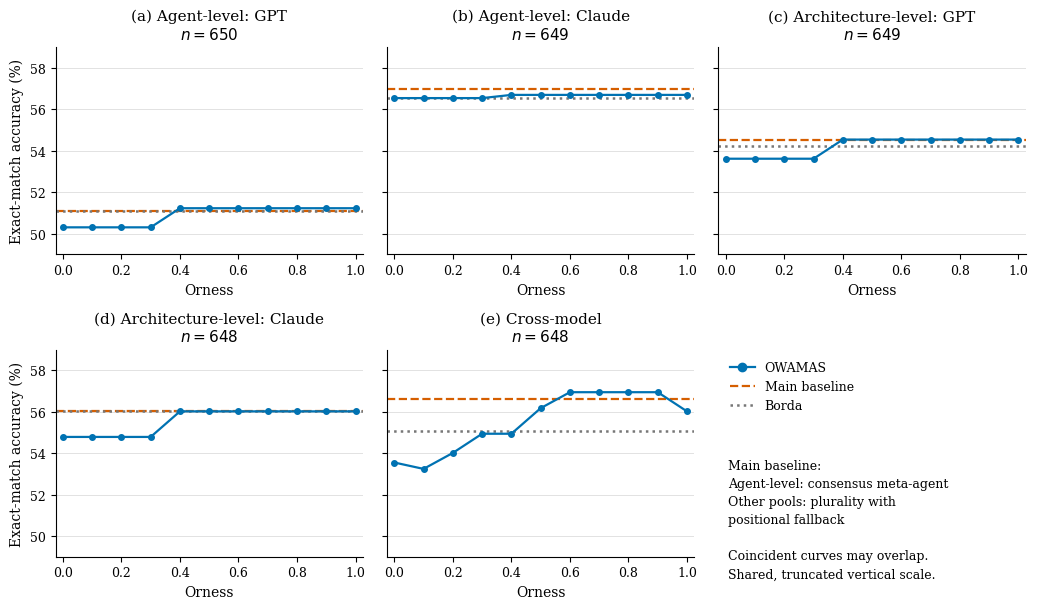

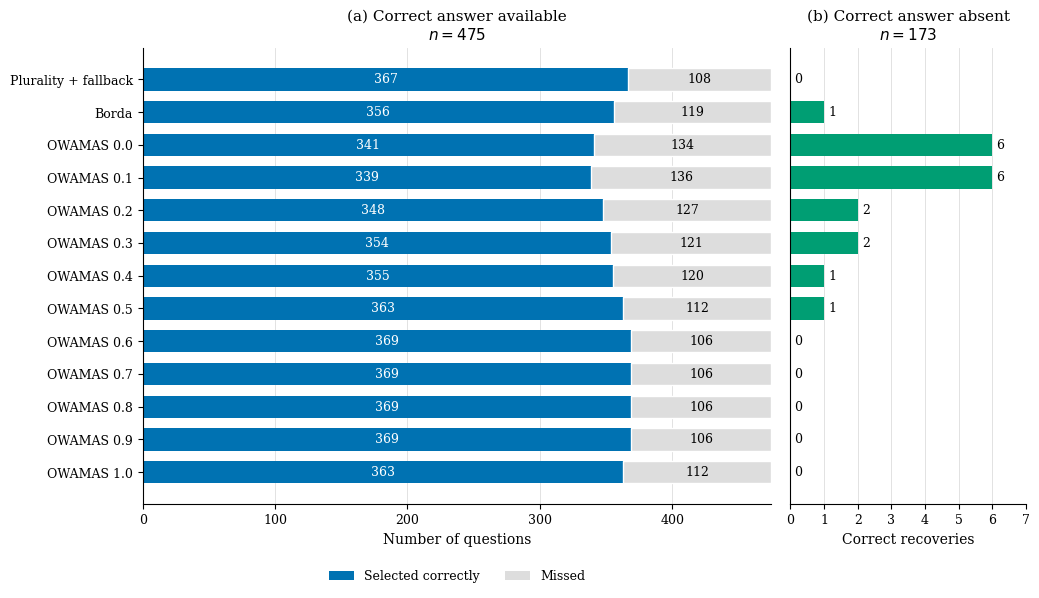


Figures saved:
/content/owamas/outputs/20261017T134646_300295Z/figures/figure_1_accuracy_by_orness.pdf
/content/owamas/outputs/20261017T134646_300295Z/figures/figure_1_accuracy_by_orness.png
/content/owamas/outputs/20261017T134646_300295Z/figures/figure_2_availability_and_selection.pdf
/content/owamas/outputs/20261017T134646_300295Z/figures/figure_2_availability_and_selection.png


In [13]:
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plot_style = {
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 300,
}

POOL_TITLES = {
    "agent_gpt": "Agent-level: GPT",
    "agent_claude": "Agent-level: Claude",
    "architecture_gpt": "Architecture-level: GPT",
    "architecture_claude": "Architecture-level: Claude",
    "cross_model": "Cross-model",
}

BLUE = "#0072B2"
ORANGE = "#D55E00"
GREEN = "#009E73"
GREY = "#777777"

saved_figure_paths = []


def save_paper_figure(fig, filename):
    for extension in ("pdf", "png"):
        destination = FIGURE_DIR / f"{filename}.{extension}"
        fig.savefig(
            destination,
            bbox_inches="tight",
            facecolor="white",
        )
        saved_figure_paths.append(destination)


with mpl.rc_context(plot_style):
    # ---------------------------------------------------------
    # Figure 1: accuracy across the full orness grid
    # ---------------------------------------------------------
    fig, axes = plt.subplots(
        2, 3,
        figsize=(10.5, 6.2),
        sharex=True,
        sharey=True,
    )
    axes = axes.ravel()

    # A shared vertical scale supports comparisons across panels.
    plotted_accuracy = accuracy_summary_df["accuracy_percent"]
    y_min = np.floor(plotted_accuracy.min()) - 1
    y_max = np.ceil(plotted_accuracy.max()) + 1

    for panel, (pool_id, pool) in enumerate(pools.items()):
        ax = axes[panel]

        pool_results = accuracy_summary_df.loc[
            accuracy_summary_df["pool_id"] == pool_id
        ]

        owamas_results = pool_results.loc[
            pool_results["method"] == "OWAMAS"
        ].sort_values("orness")

        baseline_accuracy = pool_results.loc[
            pool_results["method"] == pool["baseline_name"],
            "accuracy_percent",
        ].item()

        borda_accuracy = pool_results.loc[
            pool_results["method"] == "Borda",
            "accuracy_percent",
        ].item()

        ax.axhline(
            baseline_accuracy,
            color=ORANGE,
            linestyle="--",
            linewidth=1.6,
            zorder=2,
        )
        ax.axhline(
            borda_accuracy,
            color=GREY,
            linestyle=":",
            linewidth=1.8,
            zorder=2,
        )
        ax.plot(
            owamas_results["orness"],
            owamas_results["accuracy_percent"],
            color=BLUE,
            marker="o",
            markersize=4,
            linewidth=1.6,
            zorder=3,
        )

        ax.set_title(
            f"({chr(97 + panel)}) {POOL_TITLES[pool_id]}"
            f"\n$n={len(pool['data'])}$"
        )
        ax.set_xlim(-0.025, 1.025)
        ax.set_ylim(y_min, y_max)
        ax.set_xticks(np.linspace(0, 1, 6))
        ax.tick_params(labelbottom=True)
        ax.set_xlabel("Orness")
        ax.grid(axis="y", color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

        if panel % 3 == 0:
            ax.set_ylabel("Exact-match accuracy (%)")

    axes[5].axis("off")
    axes[5].legend(
        handles=[
            Line2D(
                [0], [0], color=BLUE, marker="o",
                linewidth=1.6, label="OWAMAS"
            ),
            Line2D(
                [0], [0], color=ORANGE, linestyle="--",
                linewidth=1.6, label="Main baseline"
            ),
            Line2D(
                [0], [0], color=GREY, linestyle=":",
                linewidth=1.8, label="Borda"
            ),
        ],
        loc="upper left",
        frameon=False,
    )
    axes[5].text(
        0.03, 0.47,
        "Main baseline:\n"
        "Agent-level: consensus meta-agent\n"
        "Other pools: plurality with\n"
        "positional fallback\n\n"
        "Coincident curves may overlap.\n"
        "Shared, truncated vertical scale.",
        transform=axes[5].transAxes,
        va="top",
        fontsize=9,
        linespacing=1.5,
    )

    fig.tight_layout()
    save_paper_figure(fig, "figure_1_accuracy_by_orness")
    plt.show()
    plt.close(fig)

    # ---------------------------------------------------------
    # Figure 2: cross-model availability and selection
    # ---------------------------------------------------------
    cross_selection = selection_summary_df.loc[
        selection_summary_df["pool_id"] == "cross_model"
    ].copy()

    baseline_id = pools["cross_model"]["baseline_name"]
    method_order = [
        baseline_id,
        "Borda",
        *[f"OWAMAS_{alpha:.1f}" for alpha in ORNESS_GRID],
    ]

    cross_selection = (
        cross_selection.set_index("method_id")
        .loc[method_order]
    )

    # Available-answer counts must be constant across methods.
    available_totals = (
        cross_selection["n_available_selected"]
        + cross_selection["n_available_missed"]
    )

    if available_totals.nunique() != 1:
        raise AssertionError("Oracle counts differ across methods.")

    n_available = int(available_totals.iloc[0])
    n_total = int(cross_selection["n_questions"].iloc[0])
    n_absent = n_total - n_available

    row_labels = [
        "Plurality + fallback",
        "Borda",
        *[f"OWAMAS {alpha:.1f}" for alpha in ORNESS_GRID],
    ]
    y_positions = np.arange(len(method_order))

    selected = cross_selection["n_available_selected"].to_numpy()
    missed = cross_selection["n_available_missed"].to_numpy()
    recovered = cross_selection["n_absent_correct"].to_numpy()

    fig, (ax_available, ax_absent) = plt.subplots(
        1, 2,
        figsize=(10.5, 6.1),
        sharey=True,
        gridspec_kw={"width_ratios": [3.2, 1.2]},
    )

    ax_available.barh(
        y_positions, selected,
        color=BLUE, height=0.68,
    )
    ax_available.barh(
        y_positions, missed,
        left=selected,
        color="#DDDDDD",
        edgecolor="white",
        height=0.68,
    )

    for y, n_selected, n_missed in zip(
        y_positions, selected, missed
    ):
        ax_available.text(
            n_selected / 2, y, str(n_selected),
            ha="center", va="center", color="white", fontsize=9,
        )
        ax_available.text(
            n_selected + n_missed / 2, y, str(n_missed),
            ha="center", va="center", fontsize=9,
        )

    ax_available.set_yticks(y_positions)
    ax_available.set_yticklabels(row_labels)
    ax_available.invert_yaxis()
    ax_available.set_xlim(0, n_available)
    ax_available.set_xlabel("Number of questions")
    ax_available.set_title(
        f"(a) Correct answer available\n$n={n_available}$"
    )
    ax_available.legend(
        handles=[
            Patch(facecolor=BLUE, label="Selected correctly"),
            Patch(facecolor="#DDDDDD", label="Missed"),
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.12),
        ncol=2,
        frameon=False,
    )

    ax_absent.barh(
        y_positions, recovered,
        color=GREEN, height=0.68,
    )
    for y, count in zip(y_positions, recovered):
        ax_absent.text(
            count + 0.12, y, str(count),
            va="center", fontsize=9,
        )

    recovery_limit = max(1, int(recovered.max())) + 1
    ax_absent.set_xlim(0, recovery_limit)
    ax_absent.xaxis.set_major_locator(
        mpl.ticker.MaxNLocator(integer=True)
    )
    ax_absent.tick_params(axis="y", left=False, labelleft=False)
    ax_absent.set_xlabel("Correct recoveries")
    ax_absent.set_title(
        f"(b) Correct answer absent\n$n={n_absent}$"
    )

    for ax in (ax_available, ax_absent):
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", color="#DDDDDD", linewidth=0.6)
        ax.set_axisbelow(True)

    fig.tight_layout()
    save_paper_figure(fig, "figure_2_availability_and_selection")
    plt.show()
    plt.close(fig)


print("\nFigures saved:")
for path in saved_figure_paths:
    print(path)

In [14]:
from google.colab import files
from zipfile import ZipFile

figure_zip = OUTPUT_DIR / "OWAMAS_paper_figures.zip"

with ZipFile(figure_zip, "w") as archive:
    for filename in [
        "figure_1_accuracy_by_orness.pdf",
        "figure_2_availability_and_selection.pdf",
    ]:
        source = FIGURE_DIR / filename
        archive.write(source, arcname=filename)

files.download(str(figure_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>